# Machine Learning Lab – PCA

**Roll No.: CH.SC.U4CSE24257**

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 2. Generate real-estate dataset

In [2]:
np.random.seed(42)

n = 500

bedrooms = np.random.randint(1, 6, n)
bathrooms = np.clip(
    bedrooms * 0.7 + np.random.normal(0, 0.4, n),
    1,
    5
)

square_feet = (
    bedrooms * 450
    + bathrooms * 150
    + np.random.normal(0, 250, n)
)

number_doors = (
    bedrooms * 2
    + np.random.normal(0, 0.4, n)
)

hardwood_floors = np.random.randint(0, 2, n)

city_center = np.random.uniform(1, 30, n)

supermarket_proximity = np.random.uniform(0.5, 15, n)

transit_accessibility = np.clip(
    10 - city_center * 0.2 + np.random.normal(0, 1, n),
    1,
    10
)

parking_spaces = np.clip(
    np.round(bedrooms / 2 + np.random.normal(0, 0.7, n)),
    0,
    4
)

property_age = np.random.randint(1, 50, n)

lot_size = square_feet * 1.5 + np.random.normal(0, 500, n)

floors = np.random.randint(1, 4, n)

balconies = np.clip(
    bedrooms - 1 + np.random.normal(0, 0.5, n),
    0,
    4
)

crime_rate = np.clip(
    3 + city_center * 0.05 + np.random.normal(0, 1, n),
    0,
    10
)

school_quality = np.clip(
    9 - city_center * 0.15 + np.random.normal(0, 1, n),
    1,
    10
)

house_price = (
    square_feet * 200
    + bedrooms * 50000
    - city_center * 10000
    + np.random.normal(0, 50000, n)
)

df = pd.DataFrame({
    'bedrooms': bedrooms,
    'bathrooms': bathrooms,
    'square_feet': square_feet,
    'number_doors': number_doors,
    'hardwood_floors': hardwood_floors,
    'city_center': city_center,
    'supermarket_proximity': supermarket_proximity,
    'transit_accessibility': transit_accessibility,
    'parking_spaces': parking_spaces,
    'property_age': property_age,
    'lot_size': lot_size,
    'floors': floors,
    'balconies': balconies,
    'crime_rate': crime_rate,
    'school_quality': school_quality,
    'house_price': house_price,
    'months_unsold': np.random.randint(1, 13, n)
})

print("Dataset generated successfully.")
print("\nDataset Shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

Dataset generated successfully.

Dataset Shape: (500, 17)

First 5 rows:
   bedrooms  bathrooms  square_feet  number_doors  hardwood_floors  \
0         4   3.322192  2556.289863      8.004141                1   
1         5   3.508402  2404.870137      9.475266                1   
2         3   2.372781  1772.679745      5.573955                1   
3         5   3.375893  2978.791694      9.877910                0   
4         5   3.629667  2815.020978      9.756195                0   

   city_center  supermarket_proximity  transit_accessibility  parking_spaces  \
0    17.990079              10.666524               4.698113             3.0   
1    19.118732              10.361622               5.251788             1.0   
2     3.081498               6.418200              10.000000             3.0   
3    20.795899               0.723226               5.566827             3.0   
4     8.016019               8.952428               8.153412             3.0   

   property_age     lot_s

## 3. Check dataset information

In [3]:
print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDescriptive Statistics:")
print(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   bedrooms               500 non-null    int32  
 1   bathrooms              500 non-null    float64
 2   square_feet            500 non-null    float64
 3   number_doors           500 non-null    float64
 4   hardwood_floors        500 non-null    int32  
 5   city_center            500 non-null    float64
 6   supermarket_proximity  500 non-null    float64
 7   transit_accessibility  500 non-null    float64
 8   parking_spaces         500 non-null    float64
 9   property_age           500 non-null    int32  
 10  lot_size               500 non-null    float64
 11  floors                 500 non-null    int32  
 12  balconies              500 non-null    float64
 13  crime_rate             500 non-null    float64
 14  school_quality         500 non-null 

## 4. Select features for PCA

In [4]:
features = [
    'bedrooms',
    'bathrooms',
    'square_feet',
    'number_doors',
    'hardwood_floors',
    'city_center',
    'supermarket_proximity',
    'transit_accessibility',
    'parking_spaces',
    'property_age',
    'lot_size',
    'floors',
    'balconies',
    'crime_rate',
    'school_quality',
    'house_price'
]

X = df[features]

## 5. Standardize the data

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nStandardized Data:")
print(pd.DataFrame(
    X_scaled,
    columns=features
).head())


Standardized Data:
   bedrooms  bathrooms  square_feet  number_doors  hardwood_floors  \
0  0.723079   1.197164     1.079067      0.715819         1.079121   
1  1.425097   1.389450     0.890268      1.232178         1.079121   
2  0.021061   0.216775     0.102019     -0.137168         1.079121   
3  1.425097   1.252618     1.605865      1.373505        -0.926680   
4  1.425097   1.514672     1.401667      1.330784        -0.926680   

   city_center  supermarket_proximity  transit_accessibility  parking_spaces  \
0     0.298450               0.709712              -1.111621        1.432038   
1     0.431723               0.636016              -0.824769       -0.469739   
2    -1.461972              -0.317117               1.635219        1.432038   
3     0.629765              -1.693604              -0.661551        1.432038   
4    -0.879298               0.295411               0.678526        1.432038   

   property_age  lot_size    floors  balconies  crime_rate  school_quality  \


## 6. Calculate covariance matrix

In [6]:
covariance_matrix = np.cov(
    X_scaled,
    rowvar=False
)

covariance_df = pd.DataFrame(
    covariance_matrix,
    index=features,
    columns=features
)

print("\nCovariance Matrix:")
print(covariance_df.round(2))


Covariance Matrix:
                       bedrooms  bathrooms  square_feet  number_doors  \
bedrooms                   1.00       0.93         0.95          0.99   
bathrooms                  0.93       1.00         0.91          0.92   
square_feet                0.95       0.91         1.00          0.94   
number_doors               0.99       0.92         0.94          1.00   
hardwood_floors           -0.05      -0.02        -0.04         -0.05   
city_center                0.09       0.08         0.08          0.08   
supermarket_proximity      0.02       0.02         0.03          0.01   
transit_accessibility     -0.08      -0.07        -0.07         -0.08   
parking_spaces             0.72       0.66         0.67          0.71   
property_age               0.07       0.06         0.08          0.07   
lot_size                   0.88       0.84         0.92          0.87   
floors                    -0.03      -0.01        -0.01         -0.04   
balconies                  0.95

## 7. Visualize covariance matrix

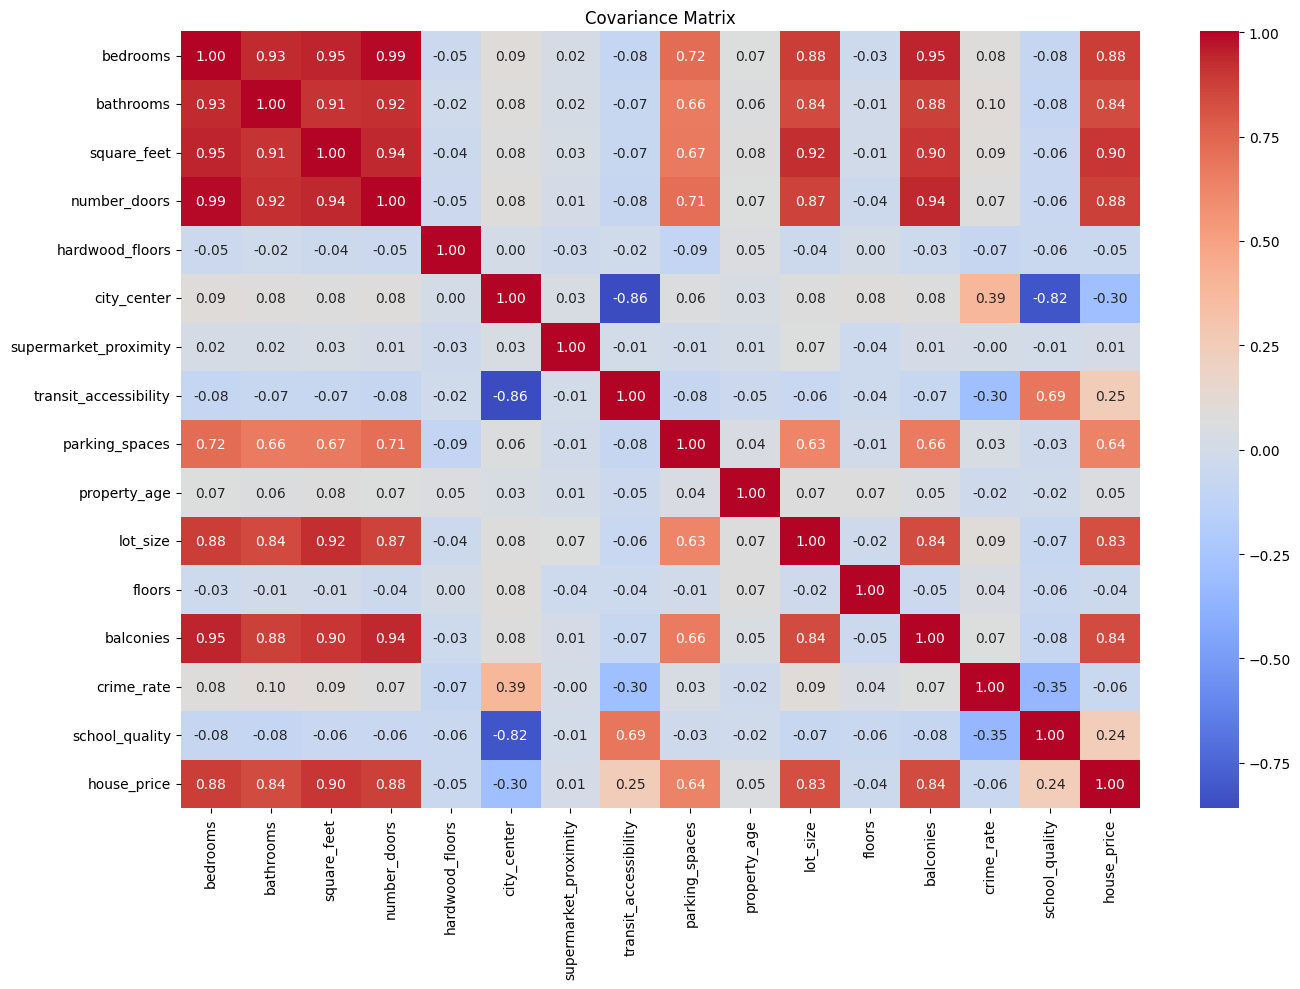

In [7]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    covariance_df,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title("Covariance Matrix")
plt.tight_layout()
plt.show()

## 8. Apply PCA

In [8]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

component_names = [
    f'PC{i+1}'
    for i in range(len(features))
]

pca_df = pd.DataFrame(
    X_pca,
    columns=component_names
)

print("\nPrincipal Components:")
print(pca_df.head())


Principal Components:
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  2.540941  0.616146 -0.165686 -1.229146 -0.437208 -1.416611 -1.163307   
1  2.530135  1.448949  0.503905 -1.716413  0.163247  0.762751  1.211583   
2  0.193368 -2.713034  0.259890  0.444545 -0.940070 -2.152639 -0.373867   
3  3.926057  0.616153 -0.526740  1.244507 -1.421879  0.314088 -0.825736   
4  3.801989 -1.810488 -0.203235  0.535529  0.790147  0.491476  0.008780   

        PC8       PC9      PC10      PC11      PC12      PC13      PC14  \
0  0.684489  0.291108  0.406420  0.384196 -0.473354  0.137444 -0.135542   
1 -0.877131 -0.088957 -0.644637  0.361268 -0.550966 -0.141855  0.401171   
2  1.436919 -0.327644  0.000799  0.353774 -0.003476 -0.213495 -0.133678   
3 -0.012991  0.212994  0.762841  0.110664  0.036636 -0.156830  0.113857   
4  0.385013  0.407634  0.395324  0.455991  0.158694  0.083215  0.255568   

       PC15      PC16  
0  0.125382 -0.061818  
1  0.005080  0.197173  
2  

## 9. Calculate explained variance

In [9]:
explained_variance = pca.explained_variance_ratio_

explained_variance_df = pd.DataFrame({
    'Principal Component': component_names,
    'Explained Variance': explained_variance,
    'Explained Variance (%)': explained_variance * 100,
    'Cumulative Variance (%)': np.cumsum(explained_variance) * 100
})

print("\nExplained Variance:")
print(explained_variance_df.round(2))


Explained Variance:
   Principal Component  Explained Variance  Explained Variance (%)  \
0                  PC1                0.43                   43.30   
1                  PC2                0.18                   18.04   
2                  PC3                0.07                    6.93   
3                  PC4                0.06                    6.40   
4                  PC5                0.06                    6.28   
5                  PC6                0.06                    5.59   
6                  PC7                0.05                    4.90   
7                  PC8                0.03                    2.89   
8                  PC9                0.02                    1.91   
9                 PC10                0.01                    1.23   
10                PC11                0.01                    0.78   
11                PC12                0.01                    0.75   
12                PC13                0.00                    0.49   

## 10. Plot explained variance

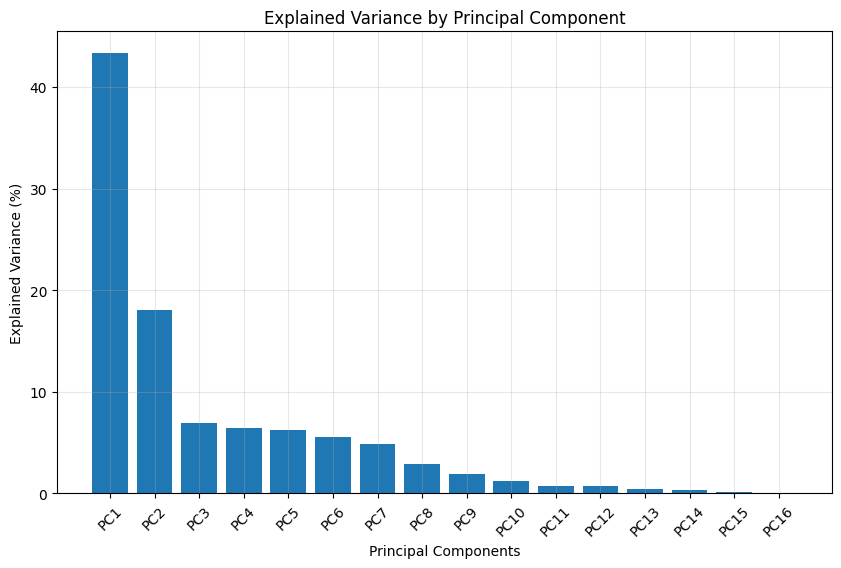

In [10]:
plt.figure(figsize=(10, 6))

plt.bar(
    component_names,
    explained_variance * 100
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance by Principal Component")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.show()

## 11. Plot cumulative explained variance

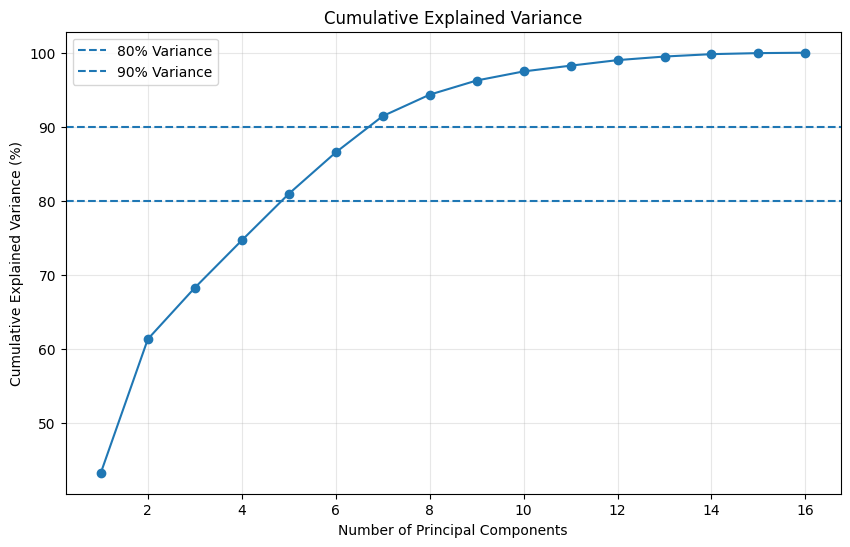

In [11]:
cumulative_variance = np.cumsum(
    explained_variance
) * 100

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(features) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=80,
    linestyle='--',
    label='80% Variance'
)

plt.axhline(
    y=90,
    linestyle='--',
    label='90% Variance'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## 12. Determine components required for 80% and 90% variance

In [12]:
components_80 = np.argmax(
    cumulative_variance >= 80
) + 1

components_90 = np.argmax(
    cumulative_variance >= 90
) + 1

print("\nPrincipal components required for 80% variance:",
      components_80)

print("Principal components required for 90% variance:",
      components_90)


Principal components required for 80% variance: 5
Principal components required for 90% variance: 7


## 13. Calculate PCA loadings

In [13]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=component_names
)

print("\nPCA Loadings:")
print(loadings.round(3))


PCA Loadings:
                         PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8  \
bedrooms               0.375  0.013  0.001 -0.008 -0.016 -0.005 -0.018 -0.049   
bathrooms              0.358  0.016  0.020 -0.012 -0.020 -0.037  0.024 -0.099   
square_feet            0.369  0.006  0.018 -0.000  0.006 -0.024  0.024 -0.143   
number_doors           0.372  0.008  0.000 -0.010 -0.025  0.006 -0.018 -0.052   
hardwood_floors       -0.021  0.014  0.536 -0.592 -0.344 -0.391  0.264  0.136   
city_center            0.024  0.563 -0.004 -0.032  0.003  0.010 -0.143 -0.017   
supermarket_proximity  0.009  0.011 -0.237 -0.459  0.798 -0.297  0.024  0.064   
transit_accessibility -0.023 -0.524 -0.016  0.069  0.025 -0.066  0.235 -0.070   
parking_spaces         0.287  0.004 -0.027  0.069 -0.019  0.040 -0.176  0.911   
property_age           0.029  0.024  0.628 -0.023  0.405  0.644  0.151  0.016   
lot_size               0.349  0.008  0.001 -0.030  0.048 -0.028  0.035 -0.178   
floors       

## 14. Visualize PCA loadings

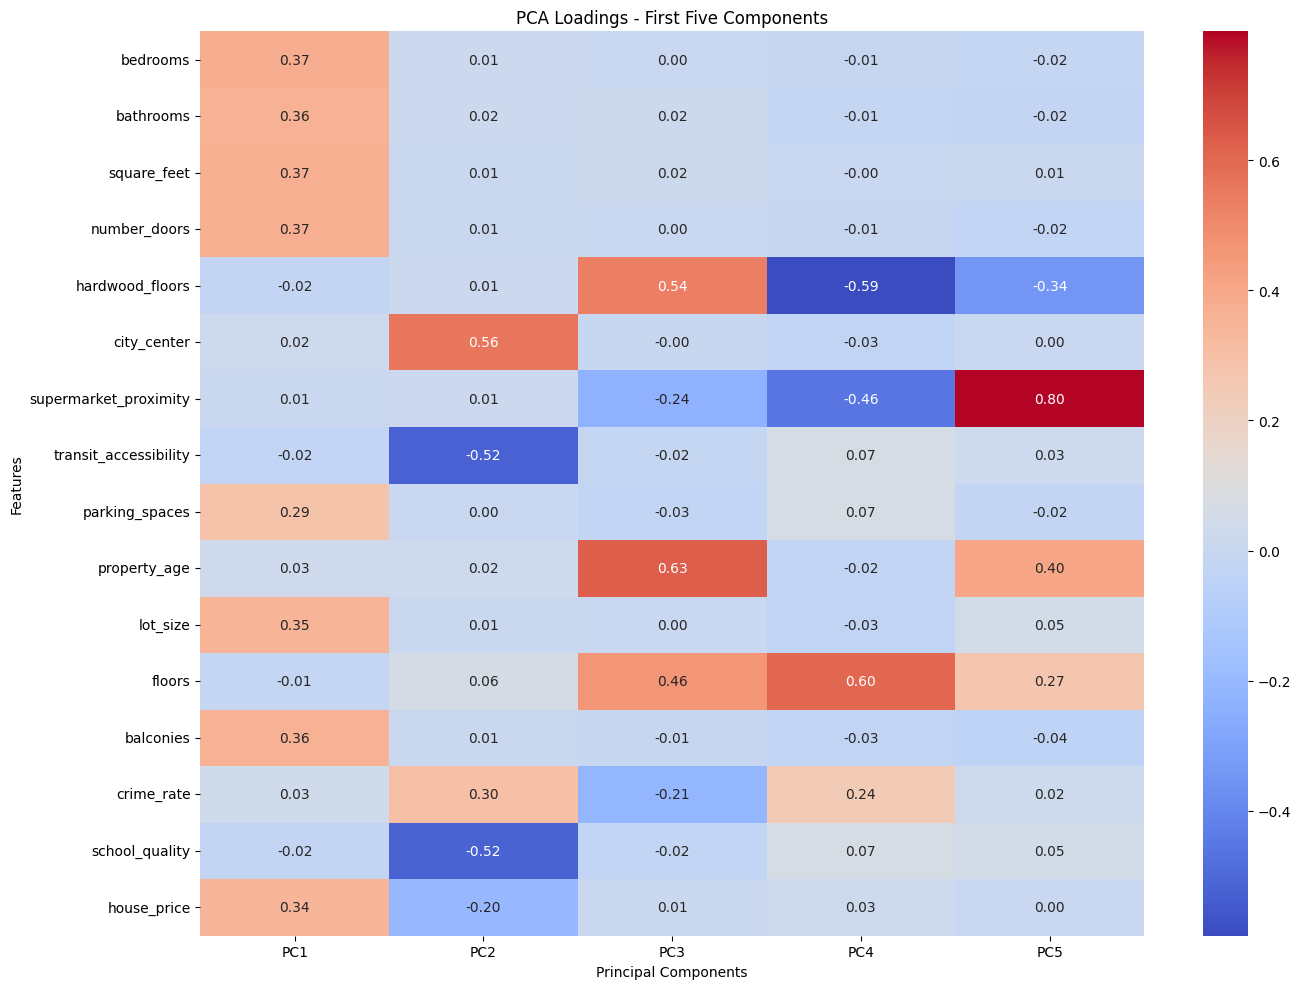

In [14]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    loadings.iloc[:, :5],
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title("PCA Loadings - First Five Components")
plt.xlabel("Principal Components")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## 15. Find important features in the first principal component

In [15]:
pc1_loadings = loadings['PC1'].abs().sort_values(
    ascending=False
)

print("\nFeatures contributing most to PC1:")
print(pc1_loadings)


Features contributing most to PC1:
bedrooms                 0.374656
number_doors             0.371707
square_feet              0.369322
balconies                0.359434
bathrooms                0.358111
lot_size                 0.349374
house_price              0.344808
parking_spaces           0.287189
crime_rate               0.032943
property_age             0.028891
city_center              0.024064
transit_accessibility    0.023389
school_quality           0.021671
hardwood_floors          0.021095
floors                   0.012192
supermarket_proximity    0.009484
Name: PC1, dtype: float64


## 16. Find important features in the second principal component

In [16]:
pc2_loadings = loadings['PC2'].abs().sort_values(
    ascending=False
)

print("\nFeatures contributing most to PC2:")
print(pc2_loadings)


Features contributing most to PC2:
city_center              0.562869
transit_accessibility    0.523511
school_quality           0.520694
crime_rate               0.301803
house_price              0.204219
floors                   0.060011
property_age             0.023612
bathrooms                0.016140
hardwood_floors          0.013890
bedrooms                 0.013027
supermarket_proximity    0.011320
balconies                0.010418
lot_size                 0.008255
number_doors             0.007676
square_feet              0.006015
parking_spaces           0.004430
Name: PC2, dtype: float64


## 17. Calculate correlation between original features and principal components

In [17]:
combined_df = pd.concat(
    [
        df[features],
        pca_df
    ],
    axis=1
)

correlation_matrix = combined_df.corr()

feature_pc_correlation = correlation_matrix.loc[
    features,
    component_names
]

print("\nCorrelation between Features and Principal Components:")
print(feature_pc_correlation.round(3))


Correlation between Features and Principal Components:
                         PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8  \
bedrooms               0.986  0.022  0.001 -0.008 -0.016 -0.005 -0.016 -0.033   
bathrooms              0.943  0.027  0.021 -0.012 -0.020 -0.035  0.022 -0.067   
square_feet            0.972  0.010  0.019 -0.000  0.006 -0.023  0.022 -0.097   
number_doors           0.978  0.013  0.000 -0.010 -0.025  0.006 -0.016 -0.035   
hardwood_floors       -0.056  0.024  0.565 -0.599 -0.345 -0.370  0.234  0.093   
city_center            0.063  0.956 -0.004 -0.032  0.003  0.009 -0.127 -0.011   
supermarket_proximity  0.025  0.019 -0.249 -0.464  0.800 -0.281  0.022  0.044   
transit_accessibility -0.062 -0.889 -0.016  0.070  0.025 -0.062  0.208 -0.047   
parking_spaces         0.756  0.008 -0.028  0.070 -0.019  0.038 -0.155  0.620   
property_age           0.076  0.040  0.662 -0.023  0.406  0.609  0.134  0.011   
lot_size               0.920  0.014  0.001 -0.030  0.

## 18. Visualize feature and principal component correlations

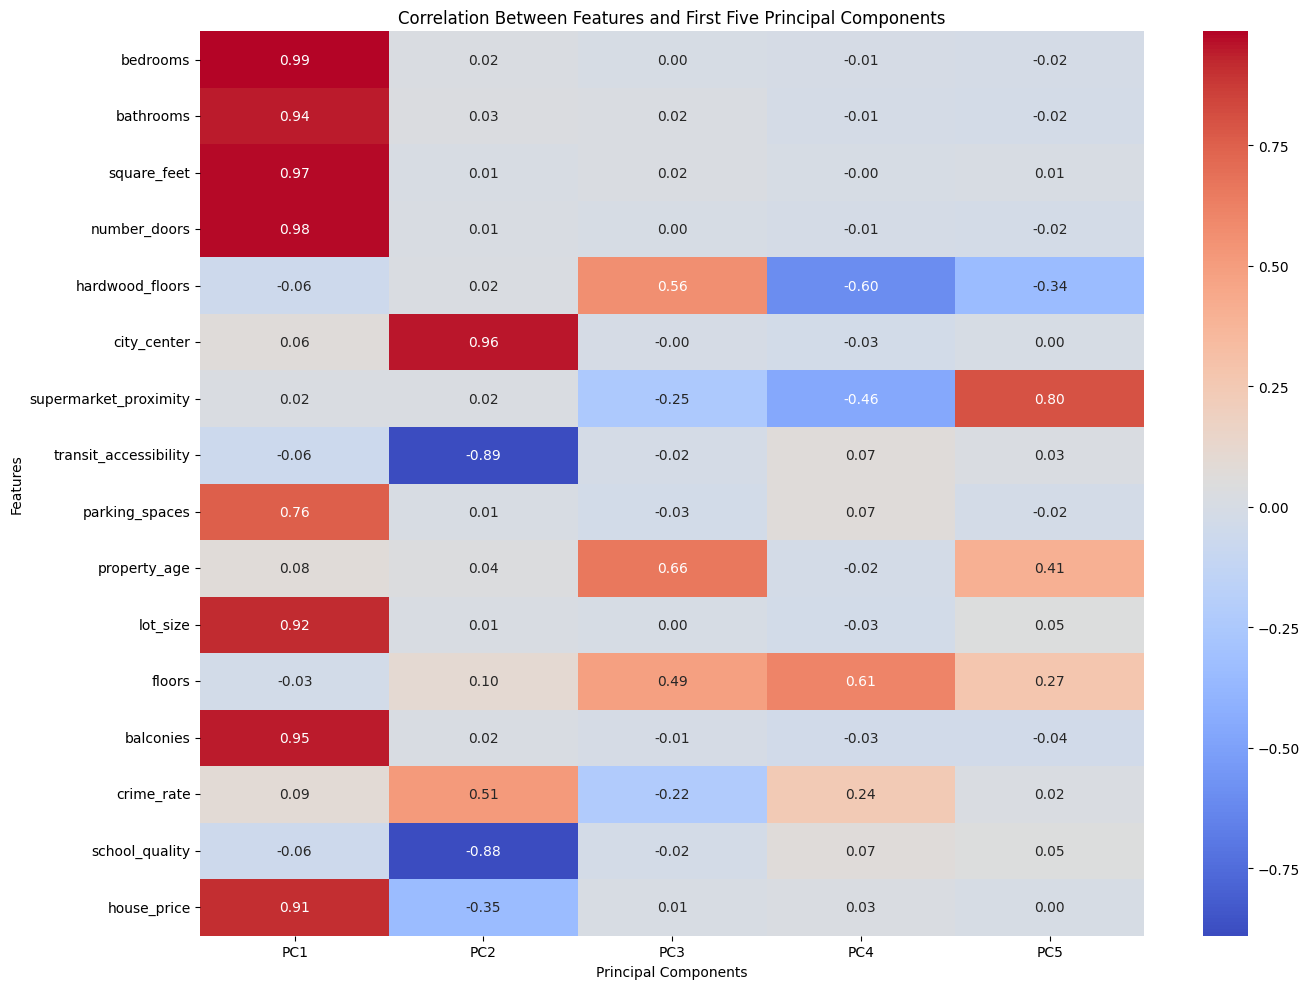

In [18]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    feature_pc_correlation.iloc[:, :5],
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title(
    "Correlation Between Features and First Five Principal Components"
)

plt.xlabel("Principal Components")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## 19. Apply Kaiser criterion

In [19]:
eigenvalues = pca.explained_variance_

eigenvalue_df = pd.DataFrame({
    'Principal Component': component_names,
    'Eigenvalue': eigenvalues
})

print("\nEigenvalues:")
print(eigenvalue_df.round(3))

kaiser_components = np.sum(
    eigenvalues > 1
)

print(
    "\nNumber of components with eigenvalue > 1:",
    kaiser_components
)


Eigenvalues:
   Principal Component  Eigenvalue
0                  PC1       6.942
1                  PC2       2.892
2                  PC3       1.111
3                  PC4       1.025
4                  PC5       1.007
5                  PC6       0.897
6                  PC7       0.786
7                  PC8       0.464
8                  PC9       0.307
9                 PC10       0.197
10                PC11       0.124
11                PC12       0.120
12                PC13       0.078
13                PC14       0.052
14                PC15       0.023
15                PC16       0.008

Number of components with eigenvalue > 1: 5


## 20. Create reduced dataset

In [20]:
reduced_pca = PCA(
    n_components=components_80
)

X_reduced = reduced_pca.fit_transform(
    X_scaled
)

reduced_columns = [
    f'PC{i+1}'
    for i in range(components_80)
]

reduced_df = pd.DataFrame(
    X_reduced,
    columns=reduced_columns
)

print("\nReduced Dataset:")
print(reduced_df.head())

print("\nOriginal Number of Features:",
      len(features))

print("Reduced Number of Features:",
      components_80)


Reduced Dataset:
        PC1       PC2       PC3       PC4       PC5
0  2.540941  0.616146 -0.165686 -1.229146 -0.437208
1  2.530135  1.448949  0.503905 -1.716413  0.163247
2  0.193368 -2.713034  0.259890  0.444545 -0.940070
3  3.926057  0.616153 -0.526740  1.244507 -1.421879
4  3.801989 -1.810488 -0.203235  0.535529  0.790147

Original Number of Features: 16
Reduced Number of Features: 5


## 21. Visualize the first two principal components

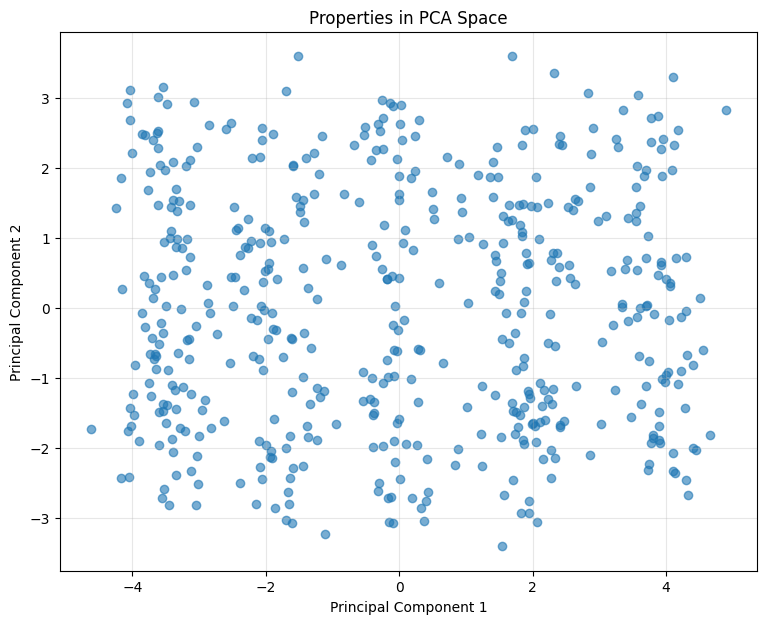

In [21]:
plt.figure(figsize=(9, 7))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Properties in PCA Space")
plt.grid(True, alpha=0.3)

plt.show()

## 22. Identify properties unsold for more than six months

In [22]:
unsold_properties = df[
    df['months_unsold'] > 6
]

print("\nProperties unsold for more than six months:")
print(
    unsold_properties[
        features + ['months_unsold']
    ].head(10)
)

print(
    "\nNumber of properties unsold for more than six months:",
    len(unsold_properties)
)


Properties unsold for more than six months:
    bedrooms  bathrooms  square_feet  number_doors  hardwood_floors  \
2          3   2.372781  1772.679745      5.573955                1   
3          5   3.375893  2978.791694      9.877910                0   
9          5   4.336955  2809.833596     10.194601                0   
12         5   3.963244  3239.379689      9.624266                1   
16         4   2.795101  1883.152566      8.612300                1   
17         5   3.141098  2491.501751     10.487505                0   
19         4   2.529135  1987.420906      8.596290                0   
23         1   1.000000   350.411490      1.879012                0   
24         1   1.000000   846.080600      1.844729                0   
26         3   1.771112  1603.300849      6.064230                1   

    city_center  supermarket_proximity  transit_accessibility  parking_spaces  \
2      3.081498               6.418200              10.000000             3.0   
3     20.79

## 23. Compare long-unsold properties with all properties

In [23]:
comparison = pd.DataFrame({
    'All Properties': df[features].mean(),
    'Unsold > 6 Months': unsold_properties[features].mean()
})

print("\nComparison of Average Property Characteristics:")
print(comparison.round(2))


Comparison of Average Property Characteristics:
                       All Properties  Unsold > 6 Months
bedrooms                         2.97               2.94
bathrooms                        2.16               2.16
square_feet                   1690.86            1655.88
number_doors                     5.96               5.93
hardwood_floors                  0.46               0.48
city_center                     15.46              15.29
supermarket_proximity            7.73               7.99
transit_accessibility            6.84               6.89
parking_spaces                   1.49               1.52
property_age                    24.45              23.83
lot_size                      2530.09            2474.62
floors                           2.01               1.99
balconies                        1.99               1.94
crime_rate                       3.77               3.73
school_quality                   6.72               6.71
house_price                 332723.83  

## 24. Calculate percentage difference

In [24]:
comparison['Percentage Difference'] = (
    (
        comparison['Unsold > 6 Months']
        - comparison['All Properties']
    )
    / comparison['All Properties'].replace(0, np.nan)
) * 100

print("\nPercentage Difference:")
print(
    comparison[
        ['Percentage Difference']
    ].sort_values(
        'Percentage Difference',
        ascending=False
    ).round(2)
)


Percentage Difference:
                       Percentage Difference
hardwood_floors                         4.73
supermarket_proximity                   3.33
parking_spaces                          1.48
transit_accessibility                   0.69
bathrooms                              -0.13
school_quality                         -0.20
number_doors                           -0.64
floors                                 -0.90
bedrooms                               -1.03
crime_rate                             -1.08
city_center                            -1.12
square_feet                            -2.07
lot_size                               -2.19
balconies                              -2.29
property_age                           -2.53
house_price                            -2.60


## 25. Conclusion

In [25]:
print("\nPCA was successfully applied to the real-estate dataset.")
print("The features were standardized before PCA.")
print("Principal components were generated to summarize the major")
print("patterns and relationships among the property characteristics.")
print("The covariance matrix, explained variance, PCA loadings,")
print("Kaiser criterion and scree-style variance plots were analyzed.")
print("Properties unsold for more than six months were also compared")
print("with the overall property dataset to identify differences.")
print("The PCA results can help identify groups of related property")
print("characteristics that may contribute to longer selling times.")


PCA was successfully applied to the real-estate dataset.
The features were standardized before PCA.
Principal components were generated to summarize the major
patterns and relationships among the property characteristics.
The covariance matrix, explained variance, PCA loadings,
Kaiser criterion and scree-style variance plots were analyzed.
Properties unsold for more than six months were also compared
with the overall property dataset to identify differences.
The PCA results can help identify groups of related property
characteristics that may contribute to longer selling times.
